# 02 — Data Preprocessing
**IDX Exchange Data Science Internship — Predicting California Home Close Prices**

Author: Saanvi Prasad

This notebook covers **Week 3**:
- Handle missing values (decide whether to drop, impute, or flag)
- Convert categorical fields to numbers (encoding)
- Normalize numerical features
- Create the train/test split: the **most recent month = test set**, and the **X months before it = training set**. Try different values of X to find the best one.
- **Deliverable:** this notebook + a cleaned CSV

## Setup

In [16]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

# >>> CHANGE THIS to the folder where your CSV files are (same as in 01_exploration) <<<
path = r"C:\Users\saanv\Desktop\idxexchange"

files = [
    "CRMLSSold202502.csv", "CRMLSSold202503.csv", "CRMLSSold202504.csv",
    "CRMLSSold202505.csv", "CRMLSSold202506.csv", "CRMLSSold202507.csv",
    "CRMLSSold202508.csv", "CRMLSSold202509.csv", "CRMLSSold202510.csv",
    "CRMLSSold202511.csv", "CRMLSSold202512.csv", "CRMLSSold202601.csv",
    "CRMLSSold202602.csv", "CRMLSSold202603.csv", "CRMLSSold202604.csv",
]

## 1. Load the data, keep single-family homes, remove duplicates
Same steps as in `01_exploration`.

In [17]:
raw = pd.concat([pd.read_csv(os.path.join(path, f), low_memory=False) for f in files], ignore_index=True)

df = raw[(raw["PropertyType"] == "Residential") & (raw["PropertySubType"] == "SingleFamilyResidence")].copy()
df = df.sort_values("CloseDate").drop_duplicates(subset="ListingKey", keep="last")

print("All rows:          ", len(raw))
print("Single-family rows:", len(df))

All rows:           324496
Single-family rows: 162454


### Keep only the columns we need
I keep the target (`ClosePrice`), the main house features, a few extra features, and location.

I **don't** use `ListPrice` or `DaysOnMarket` as features, because they only exist for homes that are for sale, and the task says the model should work for any home. I keep `ListPrice` for now only to help spot price typos.

In [18]:
keep = [
    "ListingKey", "CloseDate", "ClosePrice", "ListPrice",
    "LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet", "YearBuilt",
    "GarageSpaces", "Stories",
    "PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN",
    "City", "CountyOrParish",
]
df = df[keep].copy()
df["CloseDate"] = pd.to_datetime(df["CloseDate"])
df.head()

,ListingKey,CloseDate,ClosePrice,ListPrice,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt,GarageSpaces,Stories,PoolPrivateYN,ViewYN,FireplaceYN,NewConstructionYN,City,CountyOrParish
12956,1095569258,2025-02-01,"547,865.00","547,865.00","1,992.00",3.00,3.00,"5,870.00","2,024.00",2.00,2.00,False,False,False,True,Beaumont,Riverside
14678,1092542105,2025-02-01,"985,000.00","1,025,000.00","2,575.00",3.00,3.00,"9,250.00","1,999.00",3.00,1.00,False,True,True,False,Brentwood,Contra Costa
8771,1100982299,2025-02-01,"319,000.00","319,000.00","1,232.00",2.00,2.00,"43,560.00","1,963.00",2.00,1.00,False,True,True,False,Paradise,Butte
10063,1100577166,2025-02-01,"8,675,000.00","9,995,500.00","4,500.00",6.00,8.00,"12,071.00","2,006.00",NaN,2.00,True,True,True,False,Beverly Hills,Los Angeles
17631,1079050026,2025-02-01,"549,000.00","549,998.00","1,506.00",3.00,4.00,"6,750.00","1,948.00",2.00,1.00,False,True,False,False,Highland,San Bernardino


## 2. Remove rows that are not real sales
In Week 2 we found some prices that are clearly typos (like $989 million for a normal house) and some "sales" for $0. These rows would badly hurt a linear regression, so I remove them.

| Rule | Why |
|---|---|
| ClosePrice at least $10,000 | $0 or $1.75 is not a real sale |
| LivingArea between 300 and 20,000 sq ft | 0 sq ft or 56,500 sq ft houses are errors |
| Price per sq ft between $50 and $5,000 | catches typos in price or size |
| ClosePrice between 0.3x and 3x the ListPrice | catches the "1,000x too high" typos |

In [19]:
before = len(df)

df = df[df["ClosePrice"] >= 10000]
df = df[(df["LivingArea"] >= 300) & (df["LivingArea"] <= 20000)]

price_per_sqft = df["ClosePrice"] / df["LivingArea"]
df = df[(price_per_sqft >= 50) & (price_per_sqft <= 5000)]

ratio = df["ClosePrice"] / df["ListPrice"]
df = df[(ratio >= 0.3) & (ratio <= 3)]

print("Rows before:", before)
print("Rows after: ", len(df))
print("Removed:    ", before - len(df))
print("Price range now: $", df["ClosePrice"].min(), "to $", df["ClosePrice"].max())

Rows before: 162454
Rows after:  162091
Removed:     363
Price range now: $ 28000.0 to $ 60000000.0


Only a few hundred rows (about 0.2%) were removed, and the highest price left is now $60M, a real luxury home instead of a typo.

## 3. Fix impossible values
For some columns, one bad value shouldn't cost us the whole row. Instead, I change the bad value to **missing (NaN)** and fill it in later (step 5).

In [20]:
df.loc[(df["BedroomsTotal"] == 0) | (df["BedroomsTotal"] > 20), "BedroomsTotal"] = np.nan
df.loc[(df["BathroomsTotalInteger"] == 0) | (df["BathroomsTotalInteger"] > 20), "BathroomsTotalInteger"] = np.nan
df.loc[(df["LotSizeSquareFeet"] < 100) | (df["LotSizeSquareFeet"] > 100 * 43560), "LotSizeSquareFeet"] = np.nan  # over 100 acres
df.loc[df["YearBuilt"] < 1850, "YearBuilt"] = np.nan
df.loc[df["GarageSpaces"] > 20, "GarageSpaces"] = np.nan
df.loc[df["Stories"] > 5, "Stories"] = np.nan

# Yes/No columns: change True/False to 1/0 (blanks stay missing for now)
for col in ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]:
    df[col] = df[col].map({True: 1, False: 0, "True": 1, "False": 0})

# Add a month column (used for the train/test split)
df["Month"] = df["CloseDate"].dt.to_period("M").astype(str)

## 4. How many values are missing now?

In [21]:
missing = pd.DataFrame({
    "missing rows": df.isna().sum(),
    "% missing": (df.isna().mean() * 100).round(2),
})
missing[missing["missing rows"] > 0].sort_values("% missing", ascending=False)

,missing rows,% missing
Stories,17151,10.58
ViewYN,14637,9.03
PoolPrivateYN,12515,7.72
NewConstructionYN,12261,7.56
GarageSpaces,6301,3.89
LotSizeSquareFeet,3339,2.06
FireplaceYN,114,0.07
YearBuilt,85,0.05
BedroomsTotal,64,0.04
BathroomsTotalInteger,62,0.04


In [22]:
print("Rows with at least one missing value:", round(df.isna().any(axis=1).mean() * 100, 1), "%")

Rows with at least one missing value: 32.5 %


### Decision: drop, impute, or flag?
- If I **dropped** every row with a missing value, I would lose about **a third** of the data (mostly because of `Stories` and the yes/no columns). That's too much.
- So instead I will:
  - **Impute (fill in)** missing numbers with the **median**. The median isn't affected by extreme values the way the mean is.
  - **Flag** the columns with the most missing values (lot size, garage, stories, year built) by adding a 0/1 column like `LotSizeSquareFeet_missing`, so the model knows the value was filled in.
  - Fill missing **yes/no** values with **0** ("not reported").
  - Fill a missing **City** with "Unknown".

**Important:** the medians must come from the **training data only**. If I used the whole dataset, information from the test month would "leak" into training. So the actual filling happens *after* the split (step 7).

## 5. Save the cleaned CSV (Week 3 deliverable)
This file has all the valid single-family sales after removing bad rows and fixing impossible values. Missing values are left blank on purpose, because they get filled in with training-data medians after the split.

In [23]:
df = df.drop(columns=["ListPrice"])   # not used as a feature
df.to_csv(os.path.join(path, "cleaned_data.csv"), index=False)
print("Saved cleaned_data.csv with", len(df), "rows and", df.shape[1], "columns")

Saved cleaned_data.csv with 162091 rows and 17 columns


## 6. Train/test split by month
- **Test set** = the most recent month (April 2026)
- **Training set** = the X months right before it

We split by **time** (not randomly) because in real life we use past sales to predict future ones.

In [24]:
months = sorted(df["Month"].unique())
print("Months:", months)
print("Test month:", months[-1])

def make_split(data, test_month, X):
    """Training = the X months right before test_month. Test = test_month."""
    i = months.index(test_month)
    train_months = months[i - X : i]
    train = data[data["Month"].isin(train_months)]
    test = data[data["Month"] == test_month]
    return train, test

# Example: X = 3
train, test = make_split(df, months[-1], 3)
print("X = 3 -> training rows:", len(train), "| test rows:", len(test))

Months: ['2025-02', '2025-03', '2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12', '2026-01', '2026-02', '2026-03', '2026-04']
Test month: 2026-04
X = 3 -> training rows: 27945 | test rows: 12465


## 7. Missing values, encoding, and normalizing (fit on training data only)
This function takes a training set and a test set and:
1. **Fills missing values** using the training medians (and adds the missing flags)
2. **Takes the log** of price, living area and lot size, since they are right-skewed (Week 2)
3. **Encodes** County and City as 0/1 columns (**one-hot encoding**). There are about 1,000 cities, so cities with fewer than 100 training sales are grouped as "Other".
4. **Normalizes** the number columns with **standardization**: (value − mean) / std, using the training mean and std.

It returns `X_train, X_test, y_train, y_test`, ready for a model. The target `y` is **log(ClosePrice)**.

In [25]:
number_cols = ["LivingArea", "BedroomsTotal", "BathroomsTotalInteger", "LotSizeSquareFeet",
               "YearBuilt", "GarageSpaces", "Stories"]
flag_cols = ["LotSizeSquareFeet", "YearBuilt", "GarageSpaces", "Stories"]
yes_no_cols = ["PoolPrivateYN", "ViewYN", "FireplaceYN", "NewConstructionYN"]


def prepare(train, test):
    train = train.copy()
    test = test.copy()

    # 1. Missing values
    for col in flag_cols:                          # flag first (before filling)
        train[col + "_missing"] = train[col].isna().astype(int)
        test[col + "_missing"] = test[col].isna().astype(int)
    for col in number_cols:                        # fill with TRAINING median
        median = train[col].median()
        train[col] = train[col].fillna(median)
        test[col] = test[col].fillna(median)
    for col in yes_no_cols:
        train[col] = train[col].fillna(0)
        test[col] = test[col].fillna(0)
    train["City"] = train["City"].fillna("Unknown")
    test["City"] = test["City"].fillna("Unknown")

    # 2. Log of skewed columns
    for d in [train, test]:
        d["LivingArea"] = np.log(d["LivingArea"])
        d["LotSizeSquareFeet"] = np.log(d["LotSizeSquareFeet"])

    # 3. Encoding: keep cities with 100+ training sales, the rest become "Other"
    city_counts = train["City"].value_counts()
    big_cities = city_counts[city_counts >= 100].index
    train["City"] = train["City"].where(train["City"].isin(big_cities), "Other")
    test["City"] = test["City"].where(test["City"].isin(big_cities), "Other")

    feature_cols = number_cols + [c + "_missing" for c in flag_cols] + yes_no_cols + ["CountyOrParish", "City"]
    X_train = pd.get_dummies(train[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = pd.get_dummies(test[feature_cols], columns=["CountyOrParish", "City"], dtype=int)
    X_test = X_test.reindex(columns=X_train.columns, fill_value=0)   # same columns as train

    # 4. Normalize number columns with TRAINING mean and std
    for col in number_cols:
        mean = X_train[col].mean()
        std = X_train[col].std()
        X_train[col] = (X_train[col] - mean) / std
        X_test[col] = (X_test[col] - mean) / std

    y_train = np.log(train["ClosePrice"])
    y_test = np.log(test["ClosePrice"])
    return X_train, X_test, y_train, y_test

Let's try it once and look at the result:

In [26]:
train, test = make_split(df, months[-1], 3)
X_train, X_test, y_train, y_test = prepare(train, test)

print("X_train shape:", X_train.shape)
print("X_test shape: ", X_test.shape)
print("Missing values left in X_train:", X_train.isna().sum().sum())
print("Missing values left in X_test: ", X_test.isna().sum().sum())
X_train.head()

X_train shape: (27945, 140)
X_test shape:  (12465, 140)
Missing values left in X_train: 0
Missing values left in X_test:  0


,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt,GarageSpaces,Stories,LotSizeSquareFeet_missing,YearBuilt_missing,GarageSpaces_missing,Stories_missing,PoolPrivateYN,ViewYN,FireplaceYN,NewConstructionYN,CountyOrParish_Alameda,CountyOrParish_Amador,CountyOrParish_Butte,CountyOrParish_Calaveras,CountyOrParish_Colusa,CountyOrParish_Contra Costa,CountyOrParish_El Dorado,CountyOrParish_Fresno,CountyOrParish_Glenn,CountyOrParish_Imperial,CountyOrParish_Kern,CountyOrParish_Kings,CountyOrParish_Lake,CountyOrParish_Lassen,CountyOrParish_Los Angeles,CountyOrParish_Madera,CountyOrParish_Marin,CountyOrParish_Mariposa,CountyOrParish_Mendocino,CountyOrParish_Merced,CountyOrParish_Modoc,CountyOrParish_Mono,CountyOrParish_Monterey,CountyOrParish_Napa,CountyOrParish_Nevada,CountyOrParish_Orange,CountyOrParish_Other,CountyOrParish_Placer,CountyOrParish_Plumas,CountyOrParish_Riverside,CountyOrParish_Sacramento,CountyOrParish_San Benito,CountyOrParish_San Bernardino,CountyOrParish_San Diego,CountyOrParish_San Francisco,...,City_Huntington Beach,City_Indio,City_Irvine,City_Jurupa Valley,City_La Quinta,City_Lake Elsinore,City_Lancaster,City_Livermore,City_Long Beach,City_Los Angeles,City_Menifee,City_Merced,City_Mission Viejo,City_Moreno Valley,City_Murrieta,City_Newport Beach,City_Oakland,City_Oceanside,City_Ontario,City_Orange,City_Other,City_Oxnard,City_Palm Desert,City_Palm Springs,City_Palmdale,City_Pasadena,City_Paso Robles,City_Perris,City_Rancho Cucamonga,City_Rancho Mirage,City_Redlands,City_Riverside,City_Salinas,City_San Bernardino,City_San Diego,City_San Jacinto,City_San Jose,City_Santa Ana,City_Simi Valley,City_Temecula,City_Thousand Oaks,City_Torrance,City_Valencia,City_Ventura,City_Victorville,City_Vista,City_Whittier,City_Winchester,City_Woodland Hills,City_Yorba Linda
254147,-0.15,-0.52,-0.57,-0.64,-0.39,0.02,-0.68,0,0,0,0,0.00,0.00,1.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
248567,-1.02,-0.52,-0.57,0.20,0.00,0.02,-0.68,0,0,0,0,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
250314,-0.51,-0.52,-0.57,-0.28,-0.72,-1.10,-0.68,0,0,0,0,0.00,1.00,1.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
256107,-1.19,-0.52,-0.57,-0.42,-0.46,0.02,-0.68,0,0,0,1,0.00,0.00,0.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
247427,-0.19,-0.52,-0.57,1.11,-0.39,0.02,-0.68,0,0,0,0,0.00,1.00,1.00,0.00,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [27]:
# Check the normalizing worked: number columns should now have mean ≈ 0 and std ≈ 1
X_train[number_cols].describe().loc[["mean", "std"]].round(2)

,LivingArea,BedroomsTotal,BathroomsTotalInteger,LotSizeSquareFeet,YearBuilt,GarageSpaces,Stories
mean,-0.00,-0.00,0.00,-0.00,0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00


## 8. Finding the best X (how many training months)
More months = more data, but older months may reflect an older market. To choose X fairly, I **don't** use the test month (that would be cheating, since we'd be tuning on the test set). Instead I use the month **before** it (March 2026) as a **validation** month:

- For each X, train on the X months before March, predict March, and record the R².
- Pick the X with the best validation R².

I use a simple Linear Regression for this (it's also the Week 4 model).

In [28]:
val_month = months[-2]          # March 2026
results = []

for X in range(1, months.index(val_month) + 1):
    train, val = make_split(df, val_month, X)
    X_tr, X_val, y_tr, y_val = prepare(train, val)

    model = LinearRegression()
    model.fit(X_tr, y_tr)
    pred = np.exp(model.predict(X_val))          # back from log to dollars

    r2 = r2_score(np.exp(y_val), pred)
    results.append({"X": X, "training rows": len(train), "validation R2": round(r2, 4)})

results = pd.DataFrame(results)
results.style.format({"validation R2": "{:.4f}"})

,X,training rows,validation R2
0,1,8943,0.6006
1,2,16400,0.5918
2,3,26826,0.5957
3,4,36518,0.6147
4,5,48511,0.6102
5,6,59933,0.6646
6,7,71359,0.6753
7,8,83440,0.6765
8,9,95104,0.6816
9,10,106830,0.6878


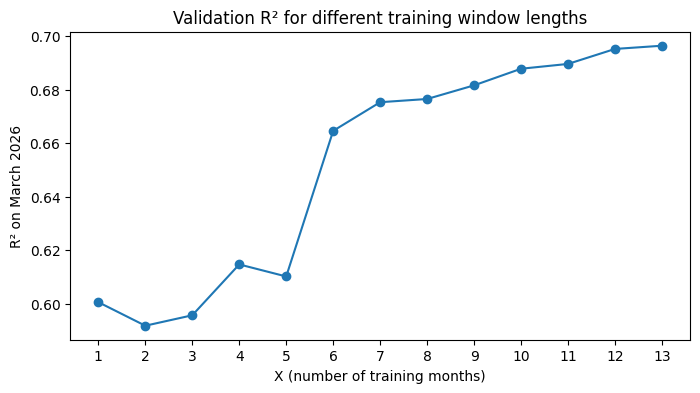

Best X: 13


In [29]:
plt.figure(figsize=(8, 4))
plt.plot(results["X"], results["validation R2"], marker="o")
plt.title("Validation R² for different training window lengths")
plt.xlabel("X (number of training months)")
plt.ylabel("R² on March 2026")
plt.xticks(results["X"])
plt.show()

best_X = int(results.loc[results["validation R2"].idxmax(), "X"])
print("Best X:", best_X)

**What I notice:** using more months keeps making the validation R² better. It goes from about **0.60** with 1 month to about **0.70** with 12–13 months. The biggest jump happens around 6 months. Even though prices changed a bit over the year, having more training data helps more. The best value is **X = 13**, so the final model trains on **March 2025 – March 2026** and is tested on **April 2026**.

## 9. Make the final split and save it

In [30]:
train, test = make_split(df, months[-1], best_X)

print("Training months:", sorted(train["Month"].unique()))
print("Test month:     ", months[-1])
print("Training rows:", len(train))
print("Test rows:    ", len(test))

train.to_csv(os.path.join(path, "train_data.csv"), index=False)
test.to_csv(os.path.join(path, "test_data.csv"), index=False)
print("Saved train_data.csv and test_data.csv")

Training months: ['2025-03', '2025-04', '2025-05', '2025-06', '2025-07', '2025-08', '2025-09', '2025-10', '2025-11', '2025-12', '2026-01', '2026-02', '2026-03']
Test month:      2026-04
Training rows: 140798
Test rows:     12465
Saved train_data.csv and test_data.csv


---
## Summary
| Step | What I did |
|---|---|
| Bad rows | Removed 363 rows that weren't real sales (typos, $0 prices) |
| Impossible values | Changed to missing (0 or 20+ bedrooms, lots over 100 acres, etc.) |
| Missing values | Filled numbers with the **training median**, added 0/1 **flags** for the columns with the most gaps, filled yes/no with 0 |
| Encoding | **One-hot encoded** County and City (rare cities grouped as "Other") |
| Normalizing | Log of price, living area and lot size, then **standardized** the number columns using training mean/std |
| Split | Test = April 2026; training = the **13 months** before it (X = 13) (chosen using March 2026 as a validation month) |

**Files saved:** `cleaned_data.csv` (cleaned dataset), `train_data.csv`, `test_data.csv`

**Next (Week 4):** train a Linear Regression on this split and record its R² on the test set → `03_baseline_model.ipynb`